<a href="https://colab.research.google.com/github/Thaer-F-Ali/Pystac_Sentinal2_CropDetection/blob/main/PySTAC_Sentinal_2_Crop_Segementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pystac-client

In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
    print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [47.15101, 30.865245, 47.211962, 30.91047]

In [6]:
search = catalog.search(
    collections=['sentinel-2-c1-l2a'],
    bbox=roi,
    datetime ='2025'
)

In [7]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [8]:
len(items)

174

In [9]:
# Showing Items structure
items[0].properties['proj:code']

'EPSG:32638'

In [10]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [11]:
!pip install -q stackstac

In [12]:
from stackstac import stack

In [13]:
layer_stack = stack(
    items,
    assets=['nir', 'red', 'scl'],
    epsg=32638,
    resolution = 10,
    bounds_latlon= roi
)

In [14]:
layer_stack

<xarray.DataArray 'stackstac-7c248161e1d9cc394c9bd6ceedcf5e84' (time: 174,
                                                                band: 3,
                                                                y: 514, x: 593)> Size: 1GB
dask.array<fetch_raster_window, shape=(174, 3, 514, 593), dtype=float64, chunksize=(1, 1, 514, 593), chunktype=numpy.ndarray>
Coordinates: (12/54)
  * time                                     (time) datetime64[ns] 1kB 2025-0...
  * band                                     (band) <U3 36B 'nir' 'red' 'scl'
  * y                                        (y) float64 4kB 3.422e+06 ... 3....
  * x                                        (x) float64 5kB 7.056e+05 ... 7....
    id                                       (time) <U30 21kB 'S2A_T38RQV_202...
    view:incidence_angle                     (time) float64 1kB 3.159 ... 6.108
    ...                                       ...
    title                                    (band) <U30 360B 'NIR 1 - 10m' ....
    gsd                                      (band) int64 24B 10 10 20
    common_name                              (band) object 24B 'nir' 'red' None
    center_wavelength                        (band) object 24B 0.842 0.665 None
    full_width_half_max                      (band) object 24B 0.145 0.038 None
    epsg                                     int64 8B 32638
Attributes:
    spec:        RasterSpec(epsg=32638, bounds=(705560, 3416640, 711490, 3421...
    crs:         epsg:32638
    transform:   | 10.00, 0.00, 705560.00|\n| 0.00,-10.00, 3421780.00|\n| 0.0...
    resolution:  10

In [15]:
ds = (
    layer_stack
    .to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop= True)
    .drop_attrs()
)

In [16]:
ds

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 174, y: 514, x: 593)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2025-01-04T07:41:08.392000 ... 2025-12...
  * y        (y) float64 4kB 3.422e+06 3.422e+06 ... 3.417e+06 3.417e+06
  * x        (x) float64 5kB 7.056e+05 7.056e+05 ... 7.115e+05 7.115e+05
Data variables:
    nir      (time, y, x) float64 424MB dask.array<chunksize=(1, 514, 593), meta=np.ndarray>
    red      (time, y, x) float64 424MB dask.array<chunksize=(1, 514, 593), meta=np.ndarray>
    scl      (time, y, x) float64 424MB dask.array<chunksize=(1, 514, 593), meta=np.ndarray>

In [17]:
mask = ds.scl.isin([0,1 , 3, 8, 9, 10, 11]).astype(int)
ds_mask = ds[['nir', 'red']].where(mask==0)


In [18]:
nir = ds_mask['nir']
red = ds_mask['red']
ndvi = (nir-red)/(nir+red)

In [19]:
ndvi_monthly = ndvi.resample(time = 'ME').max('time')

In [20]:
ndvi_mean = ndvi_monthly.mean(dim = 'time')

In [21]:
from dask.diagnostics import ProgressBar

In [22]:
import warnings
warnings.filterwarnings('ignore',category= RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [23]:
with ProgressBar():
    ndvi_mean = ndvi_mean.compute()

[########################################] | 100% Completed | 206.43 s


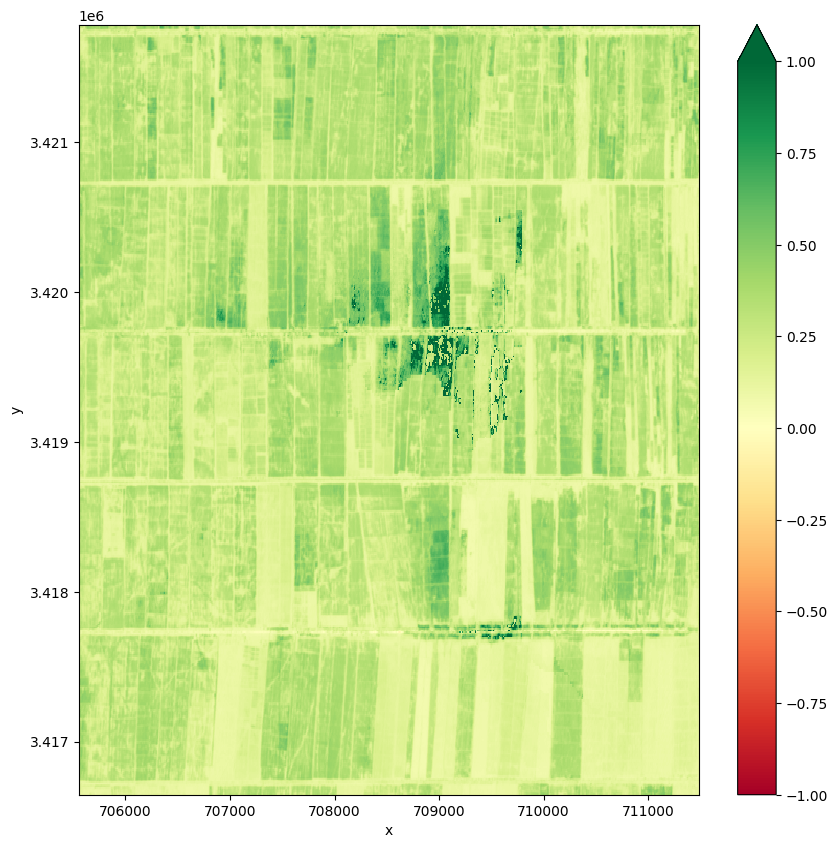

In [24]:
ndvi_mean.plot(
    robust = True,
    figsize = (10,10),
    cmap = 'RdYlGn',
    vmin = -1,
    vmax = 1
)

In [25]:
!pip install skimage.segmenation

ERROR: Could not find a version that satisfies the requirement skimage.segmenation (from versions: none)
ERROR: No matching distribution found for skimage.segmenation


In [26]:
from skimage.segmentation import felzenszwalb

In [27]:
import  xarray as xr

In [28]:
from scipy.ndimage import mean

In [29]:
labels = felzenszwalb(
    ndvi_mean.values,
    scale = 100,
    sigma = 0.1,
    min_size = 30,
    channel_axis = None
)

In [30]:
segments = xr.DataArray(
    labels,
    dims = ndvi_mean.dims,
    coords = ndvi_mean.coords
)

In [31]:
ndvi_mean_seg = mean(
    ndvi_mean,
    labels = segments,
    index = segments
    )
ndvi_mean_seg = xr.DataArray(
    ndvi_mean_seg,
    dims = ndvi_mean.dims,
    coords = ndvi_mean.coords
)

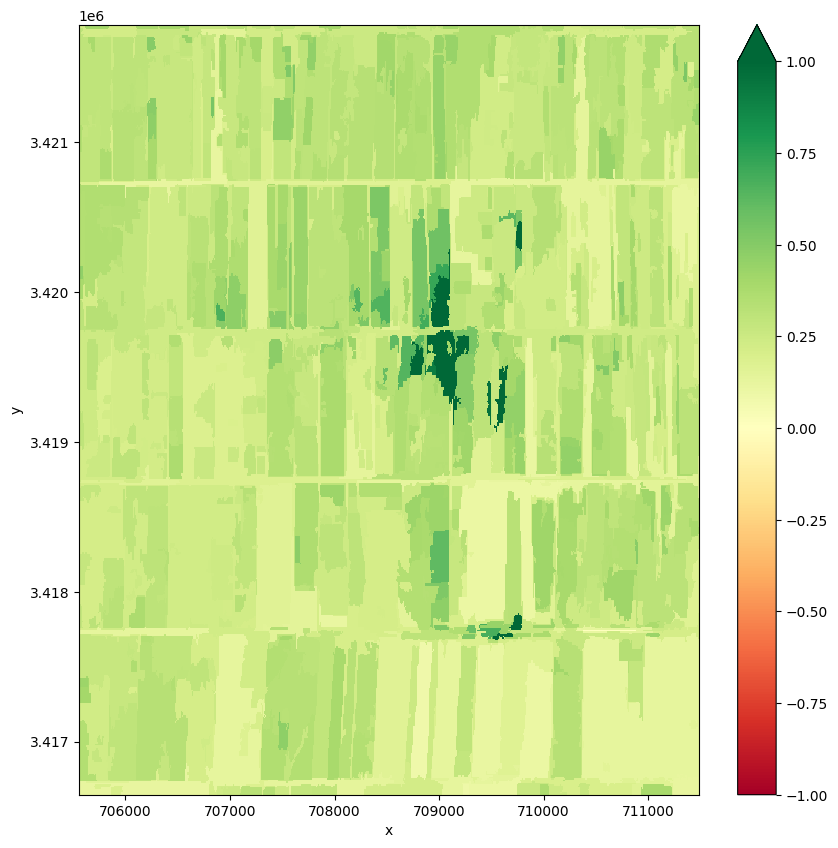

In [32]:
ndvi_mean_seg.plot(
    robust = True,
    figsize = (10,10),
    cmap = 'RdYlGn',
    vmin = -1,
    vmax = 1
)

In [33]:
# Comparing both images in the same plot
import matplotlib.pyplot as plt

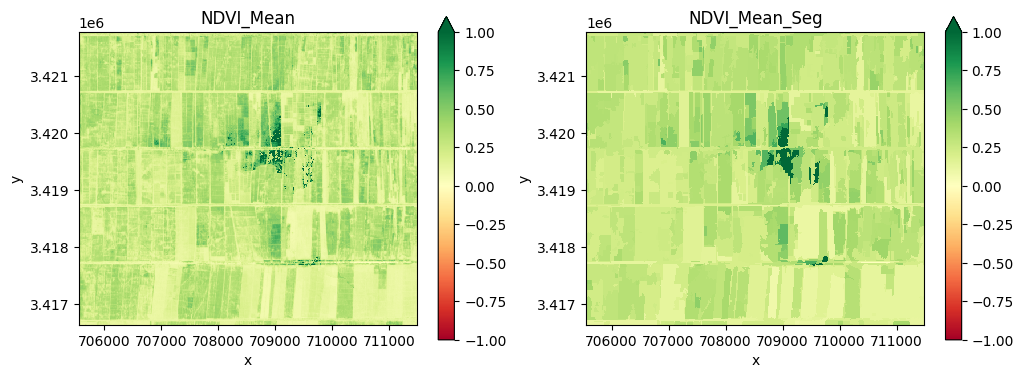

In [53]:
fig, ax = plt.subplots(1,2, figsize = (12,12))

ndvi_mean.plot(
    ax = ax[0],
    robust = True,
    cmap = 'RdYlGn',
    vmin = -1,
    vmax = 1,
    cbar_kwargs = {'shrink': 0.35}
)
ax[0].set_title('NDVI_Mean')

ndvi_mean_seg.plot(
    ax = ax[1],
    robust = True,
    cmap = 'RdYlGn',
    vmin = -1,
    vmax = 1,
    cbar_kwargs = {'shrink': 0.35},

)
ax[1].set_title('NDVI_Mean_Seg')
for a in ax:
  a.set_aspect('equal', adjustable = 'box')
plt.savefig('ndvi_mean_seg1.png', dpi = 360, bbox_inches= 'tight')

In [54]:
# Saving the figure
plt.savefig('ndvi_mean_seg.png', dpi = 360, bbox_inches= 'tight')

<Figure size 640x480 with 0 Axes>